In [2]:

import os
import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F


In [3]:

CHAR_LIST = ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'N', 'T']
CHAR2IDX = {c: i + 1 for i, c in enumerate(CHAR_LIST)}  # 0 is reserved for CTC blank
IDX2CHAR = {i + 1: c for i, c in enumerate(CHAR_LIST)}
NUM_CLASSES = len(CHAR_LIST) + 1  # for CTC blank

MAX_LABEL_LEN = 10
IMG_H, IMG_W = 36, 128

In [4]:

class OCRDataset(Dataset):
    def __init__(self, df, img_dir):
        self.df = df.reset_index(drop=True)
        self.img_dir = img_dir

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = os.path.join(self.img_dir, row['img_id'])
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        img = cv2.resize(img, (IMG_W, IMG_H))
        img = img.astype(np.float32) / 255.0
        img = np.expand_dims(img, axis=0)

        label = [CHAR2IDX[c] for c in row['text']]
        return torch.FloatTensor(img), torch.LongTensor(label), row['text']

def ocr_collate_fn(batch):
    images, labels, texts = zip(*batch)
    images = torch.stack(images)

    label_lengths = torch.IntTensor([len(label) for label in labels])
    labels_concat = torch.cat(labels)
    input_lengths = torch.full(size=(images.size(0),), fill_value=IMG_W // 4, dtype=torch.int)

    return {
        'images': images,
        'labels': labels_concat,
        'input_lengths': input_lengths,
        'label_lengths': label_lengths,
        'texts': texts
    }

In [5]:
import torch
import torch.nn as nn

class OCRModel(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        # ======================================
        # 7-Layer CNN Feature Extractor
        # ======================================
        self.cnn = nn.Sequential(

            # Layer 1
            nn.Conv2d(1,32,3,padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            # Layer 2
            nn.Conv2d(32,32,3,padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2,2),      # 36x128 -> 18x64

            # Layer 3
            nn.Conv2d(32,64,3,padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            # Layer 4
            nn.Conv2d(64,64,3,padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2,2),      # 18x64 -> 9x32

            # Layer 5
            nn.Conv2d(64,128,3,padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            # Layer 6
            nn.Conv2d(128,128,3,padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            # Layer 7
            nn.Conv2d(128,256,3,padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
        )

        # ======================================
        # GRU Sequence Model
        # ======================================

        self.gru = nn.GRU(
            input_size=256*9,
            hidden_size=256,
            num_layers=2,
            bidirectional=True,
            batch_first=True,
            dropout=0.3
        )

        self.fc = nn.Linear(
            256*2,
            num_classes
        )

    def forward(self,x):

        x = self.cnn(x)

        b,c,h,w = x.size()

        # width becomes sequence dimension

        x = x.permute(0,3,1,2)

        x = x.contiguous().view(
            b,
            w,
            c*h
        )

        x,_ = self.gru(x)

        x = self.fc(x)

        return x.log_softmax(2)

In [6]:


def greedy_decoder(preds):
    pred_indices = preds.argmax(2).detach().cpu().numpy()
    pred_texts = []
    for pred in pred_indices:
        prev = -1
        decoded = ''
        for p in pred:
            if p != prev and p != 0:
                decoded += IDX2CHAR.get(p, '')
            prev = p
        pred_texts.append(decoded)
    return pred_texts


In [7]:
def compute_accuracy(preds, truths):
    total_chars, correct_chars, exact_matches = 0, 0, 0
    for pred, true in zip(preds, truths):
        total_chars += len(true)
        correct_chars += sum(p == t for p, t in zip(pred, true))
        if pred == true:
            exact_matches += 1
    return correct_chars / total_chars, exact_matches / len(truths)

In [9]:
df = pd.read_csv("D:\License_plate_detection_algorithm\license-plate-recognition\data\Licplatesrecognition_train.csv")
train_df, val_df = train_test_split(df, test_size=0.1, random_state=42)

train_ds = OCRDataset(train_df, "D:\License_plate_detection_algorithm\license-plate-recognition\data\license_plates_recognition_train")
val_ds = OCRDataset(val_df, "D:\License_plate_detection_algorithm\license-plate-recognition\data\license_plates_recognition_train")

train_dl = DataLoader(train_ds, batch_size=16, shuffle=True, collate_fn=ocr_collate_fn)
val_dl = DataLoader(val_ds, batch_size=16, shuffle=False, collate_fn=ocr_collate_fn)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = OCRModel(NUM_CLASSES).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
ctc_loss = nn.CTCLoss(blank=0, zero_infinity=True)

In [10]:

NUM_EPOCHS = 50
for epoch in range(1, NUM_EPOCHS + 1):
    model.train()
    total_loss = 0
    for batch in train_dl:
        images = batch['images'].to(device)
        labels = batch['labels'].to(device)
        input_lengths = batch['input_lengths']
        label_lengths = batch['label_lengths']

        optimizer.zero_grad()
        output = model(images)
        loss = ctc_loss(output.permute(1, 0, 2), labels, input_lengths, label_lengths)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    print(f"📘 Epoch {epoch} - Train Loss: {total_loss / len(train_dl):.4f}")


📘 Epoch 1 - Train Loss: 2.5877
📘 Epoch 2 - Train Loss: 2.2015
📘 Epoch 3 - Train Loss: 1.3802
📘 Epoch 4 - Train Loss: 0.4811
📘 Epoch 5 - Train Loss: 0.2652
📘 Epoch 6 - Train Loss: 0.1581
📘 Epoch 7 - Train Loss: 0.1223
📘 Epoch 8 - Train Loss: 0.1095
📘 Epoch 9 - Train Loss: 0.0842
📘 Epoch 10 - Train Loss: 0.0646
📘 Epoch 11 - Train Loss: 0.0768
📘 Epoch 12 - Train Loss: 0.0772
📘 Epoch 13 - Train Loss: 0.0378
📘 Epoch 14 - Train Loss: 0.0290
📘 Epoch 15 - Train Loss: 0.0245
📘 Epoch 16 - Train Loss: 0.0238
📘 Epoch 17 - Train Loss: 0.0241
📘 Epoch 18 - Train Loss: 0.0256
📘 Epoch 19 - Train Loss: 0.0236
📘 Epoch 20 - Train Loss: 0.0360
📘 Epoch 21 - Train Loss: 0.0164
📘 Epoch 22 - Train Loss: 0.0269
📘 Epoch 23 - Train Loss: 0.0252
📘 Epoch 24 - Train Loss: 0.0182
📘 Epoch 25 - Train Loss: 0.0166
📘 Epoch 26 - Train Loss: 0.0157
📘 Epoch 27 - Train Loss: 0.0114
📘 Epoch 28 - Train Loss: 0.0073
📘 Epoch 29 - Train Loss: 0.0218
📘 Epoch 30 - Train Loss: 0.0179
📘 Epoch 31 - Train Loss: 0.0154
📘 Epoch 32 - Trai

In [11]:

model.eval()
all_preds, all_texts = [], []
with torch.no_grad():
    for batch in val_dl:
        images = batch['images'].to(device)
        texts = batch['texts']
        output = model(images)
        decoded = greedy_decoder(output)
        all_preds.extend(decoded)
        all_texts.extend(texts)

char_acc, exact_acc = compute_accuracy(all_preds, all_texts)

print("\n📊 Final Evaluation Metrics:")
print(f"✅ Character-Level Accuracy: {char_acc:.4f}")
print(f"✅ Exact String Match Accuracy: {exact_acc:.4f}")

# Show sample predictions
print("\n🔎 Sample Predictions vs Ground Truth:")
for true, pred in list(zip(all_texts, all_preds))[:10]:
    print(f"True : {true} | Pred : {pred}")


📊 Final Evaluation Metrics:
✅ Character-Level Accuracy: 0.9634
✅ Exact String Match Accuracy: 0.8778

🔎 Sample Predictions vs Ground Truth:
True : 161T3015 | Pred : 161T3015
True : 160T5065 | Pred : 160T5065
True : 133T9933 | Pred : 133T9933
True : 165T895 | Pred : 165T895
True : 109T2328 | Pred : 109T2328
True : 161T3747 | Pred : 161T3747
True : 160T2955 | Pred : 160T2955
True : 78T3293 | Pred : 78T3293
True : 123T3112 | Pred : 123T112
True : 142T7100 | Pred : 142T7100


In [12]:
# Assume all_texts (true labels) and all_preds (predicted texts) are available and same length

# 1. Exact Match Count
exact_matches = sum([true == pred for true, pred in zip(all_texts, all_preds)])
total_samples = len(all_texts)
exact_match_accuracy = exact_matches / total_samples

# 2. Character-Level Accuracy
def char_level_accuracy(true_texts, pred_texts):
    total_chars = 0
    correct_chars = 0
    for true, pred in zip(true_texts, pred_texts):
        total_chars += len(true)
        correct_chars += sum(t == p for t, p in zip(true, pred))
    return correct_chars / total_chars if total_chars else 0

char_accuracy = char_level_accuracy(all_texts, all_preds)

# 3. Print Results
print("📊 Final Evaluation Metrics:")
print(f"✅ Exact String Matches: {exact_matches} / {total_samples}")
print(f"🎯 Exact Match Accuracy: {exact_match_accuracy:.4f}")
print(f"✅ Character-Level Accuracy: {char_accuracy:.4f}")

# 4. 🔍 Sample Predictions
print("\n🔎 Sample Predictions vs Ground Truth:")
for true, pred in list(zip(all_texts, all_preds))[:10]:
    print(f"True : {true} | Pred : {pred}")


📊 Final Evaluation Metrics:
✅ Exact String Matches: 79 / 90
🎯 Exact Match Accuracy: 0.8778
✅ Character-Level Accuracy: 0.9634

🔎 Sample Predictions vs Ground Truth:
True : 161T3015 | Pred : 161T3015
True : 160T5065 | Pred : 160T5065
True : 133T9933 | Pred : 133T9933
True : 165T895 | Pred : 165T895
True : 109T2328 | Pred : 109T2328
True : 161T3747 | Pred : 161T3747
True : 160T2955 | Pred : 160T2955
True : 78T3293 | Pred : 78T3293
True : 123T3112 | Pred : 123T112
True : 142T7100 | Pred : 142T7100


In [13]:

torch.save(model.state_dict(), 'D:\License_plate_detection_algorithm\license-plate-recognition\crnn_license_plate_ocr3.pth')
print("✅ Model saved!")

✅ Model saved!


In [22]:
img=r"D:\License_plate_detection_algorithm\license-plate-recognition\data\license_plates_recognition_train\0.jpg"


In [21]:
print(dir(val_dl))

['_DataLoader__initialized', '_DataLoader__multiprocessing_context', '_IterableDataset_len_called', '__annotations__', '__class__', '__class_getitem__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__firstlineno__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__iter__', '__le__', '__len__', '__lt__', '__module__', '__ne__', '__new__', '__orig_bases__', '__parameters__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__static_attributes__', '__str__', '__subclasshook__', '__weakref__', '_auto_collation', '_dataset_kind', '_get_iterator', '_index_sampler', '_iterator', 'batch_sampler', 'batch_size', 'check_worker_number_rationality', 'collate_fn', 'dataset', 'drop_last', 'generator', 'in_order', 'multiprocessing_context', 'num_workers', 'persistent_workers', 'pin_memory', 'pin_memory_device', 'prefetch_factor', 'sampler', 'timeout', 'worker_init_fn']


Prediction: 117T3989


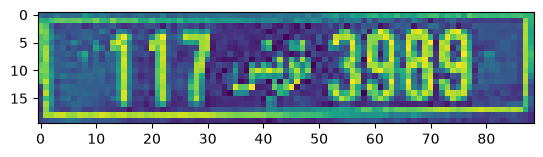

In [26]:
def predict_plate(image_path):

    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    plt.imshow(img)

    if img is None:
        raise ValueError(f"Cannot read {image_path}")

    img = cv2.resize(img, (128, 36))

    img = img.astype(np.float32) / 255.0

    img = np.expand_dims(img, axis=(0, 1))

    tensor = torch.FloatTensor(img).to(device)

    model.eval()

    with torch.no_grad():
        preds = model(tensor)

    return greedy_decoder(preds)[0]


plate_text = predict_plate(r"D:\License_plate_detection_algorithm\license-plate-recognition\data\license_plates_recognition_train\0.jpg")

print("Prediction:", plate_text)